# Đề tài 3 – Phân loại tin nhắn rác (SMS Spam)
Notebook này gọi các module trong `src/` theo từng bước của pipeline: **EDA → tiền xử lý → mô hình → đánh giá → phân tích lỗi → dự đoán**.

- Chạy từng ô theo thứ tự (Shift+Enter).
- Cần có `data/SMSSpamCollection` (giải nén từ `sms_spam_collection.zip`).
- Các bảng/hình/mô hình đã có sẵn trong `results/` và `models/`. Nếu muốn **huấn luyện lại từ đầu** (~10 phút), đặt `RUN_FULL = True` ở mục 5.

## 0. Thiết lập

In [11]:
import sys, json, warnings
from pathlib import Path
import pandas as pd

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)

# Tự động tìm thư mục gốc chứa cả thư mục 'src' và 'data' bất kể notebook nằm ở đâu
ROOT = Path.cwd()
while not (ROOT / "src").exists() and not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

# Nếu vẫn không thấy, ép buộc dùng đường dẫn tuyệt đối CHUẨN XÁC tới thư mục gốc dự án (không trỏ vào file hay data)
if not (ROOT / "src").exists():
    ROOT = Path(r"E:\Nam Tran\Tài liệu\Học máy\sms_spam_project\sms_spam")

sys.path.insert(0, str(ROOT / "src"))

# Chỉ tạo các THƯ MỤC thực sự
(ROOT / "data").mkdir(parents=True, exist_ok=True)
(ROOT / "results" / "figures").mkdir(parents=True, exist_ok=True)
(ROOT / "results" / "tables").mkdir(parents=True, exist_ok=True)

from data import load_raw, load_dataset, split, clean_text, RANDOM_STATE
from models import make_vectorizer, make_pipeline, evaluate

FIG, TAB = ROOT / "results" / "figures", ROOT / "results" / "tables"

# Kiểm tra file dữ liệu
data_file = ROOT / "data" / "SMSSpamCollection"
if not data_file.exists():
    print(f"⚠️ CẢNH BÁO: Không tìm thấy file tại: {data_file.resolve()}")
    print("👉 Hãy chắc chắn file SMSSpamCollection nằm trực tiếp trong thư mục data/!")
else:
    print("✅ Đã tìm thấy dữ liệu thành công!")

assert data_file.exists(), "Thiếu data/SMSSpamCollection – xem README.md"
print("Thư mục dự án:", ROOT, "| random_state =", RANDOM_STATE)

✅ Đã tìm thấy dữ liệu thành công!
Thư mục dự án: E:\Nam Tran\Tài liệu\Học máy\sms_spam_project\sms_spam | random_state = 42


## 1. Dữ liệu và EDA

In [2]:
raw = load_raw()
print("Kích thước:", raw.shape, "| thiếu:", int(raw.isna().sum().sum()))
print(raw["label"].value_counts().to_dict())
print("Tin trùng văn bản:", int(raw.duplicated("text").sum()),
      "| cặp trùng bị gán nhãn mâu thuẫn:", int((raw.groupby("text")["label"].nunique() > 1).sum()))
raw.sample(5, random_state=1)

Kích thước: (5574, 2) | thiếu: 0
{'ham': 4827, 'spam': 747}
Tin trùng văn bản: 403 | cặp trùng bị gán nhãn mâu thuẫn: 0


,label,text
1447,ham,Looks like u wil b getting a headstart im leaving here bout 2.30ish but if u r despera...
2032,ham,"I noe la... U wana pei bf oso rite... K lor, other days den..."
4432,ham,2mro i am not coming to gym machan. Goodnight.
4888,spam,Todays Vodafone numbers ending with 4882 are selected to a receive a Â£350 award. If y...
5276,ham,"Hi. Hope ur day * good! Back from walk, table booked for half eight. Let me know when ..."


In [3]:
df = load_dataset(drop_duplicates=True)
print("Sau khi loại trùng:", len(df), df["label"].value_counts().to_dict(), f"| tỉ lệ spam = {df['y'].mean():.3%}")

Sau khi loại trùng: 5171 {'ham': 4518, 'spam': 653} | tỉ lệ spam = 12.628%


Hình EDA (sinh bởi `src/eda.py`; chạy lại bằng `python src/eda.py`):

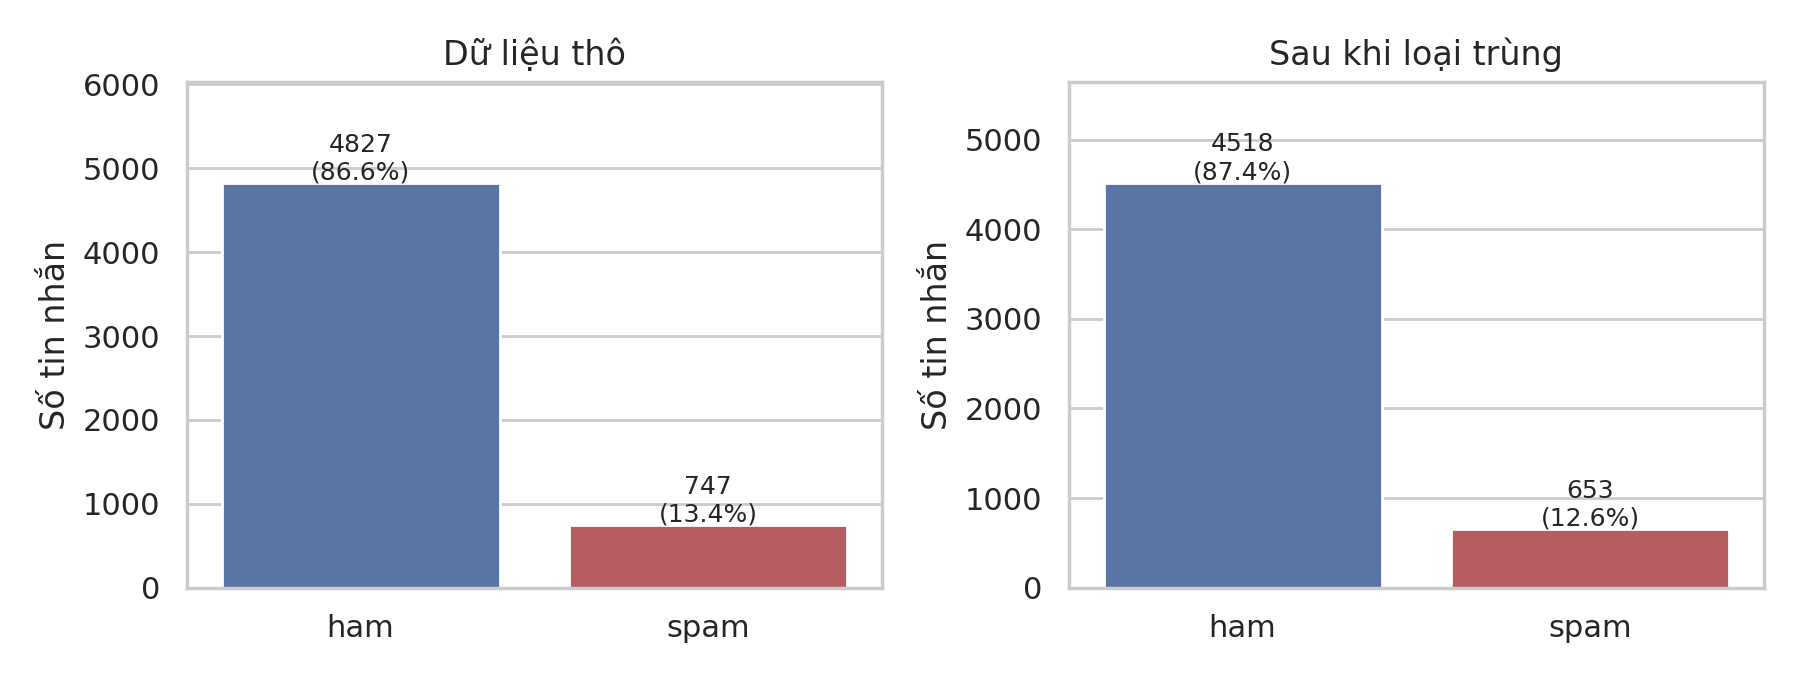

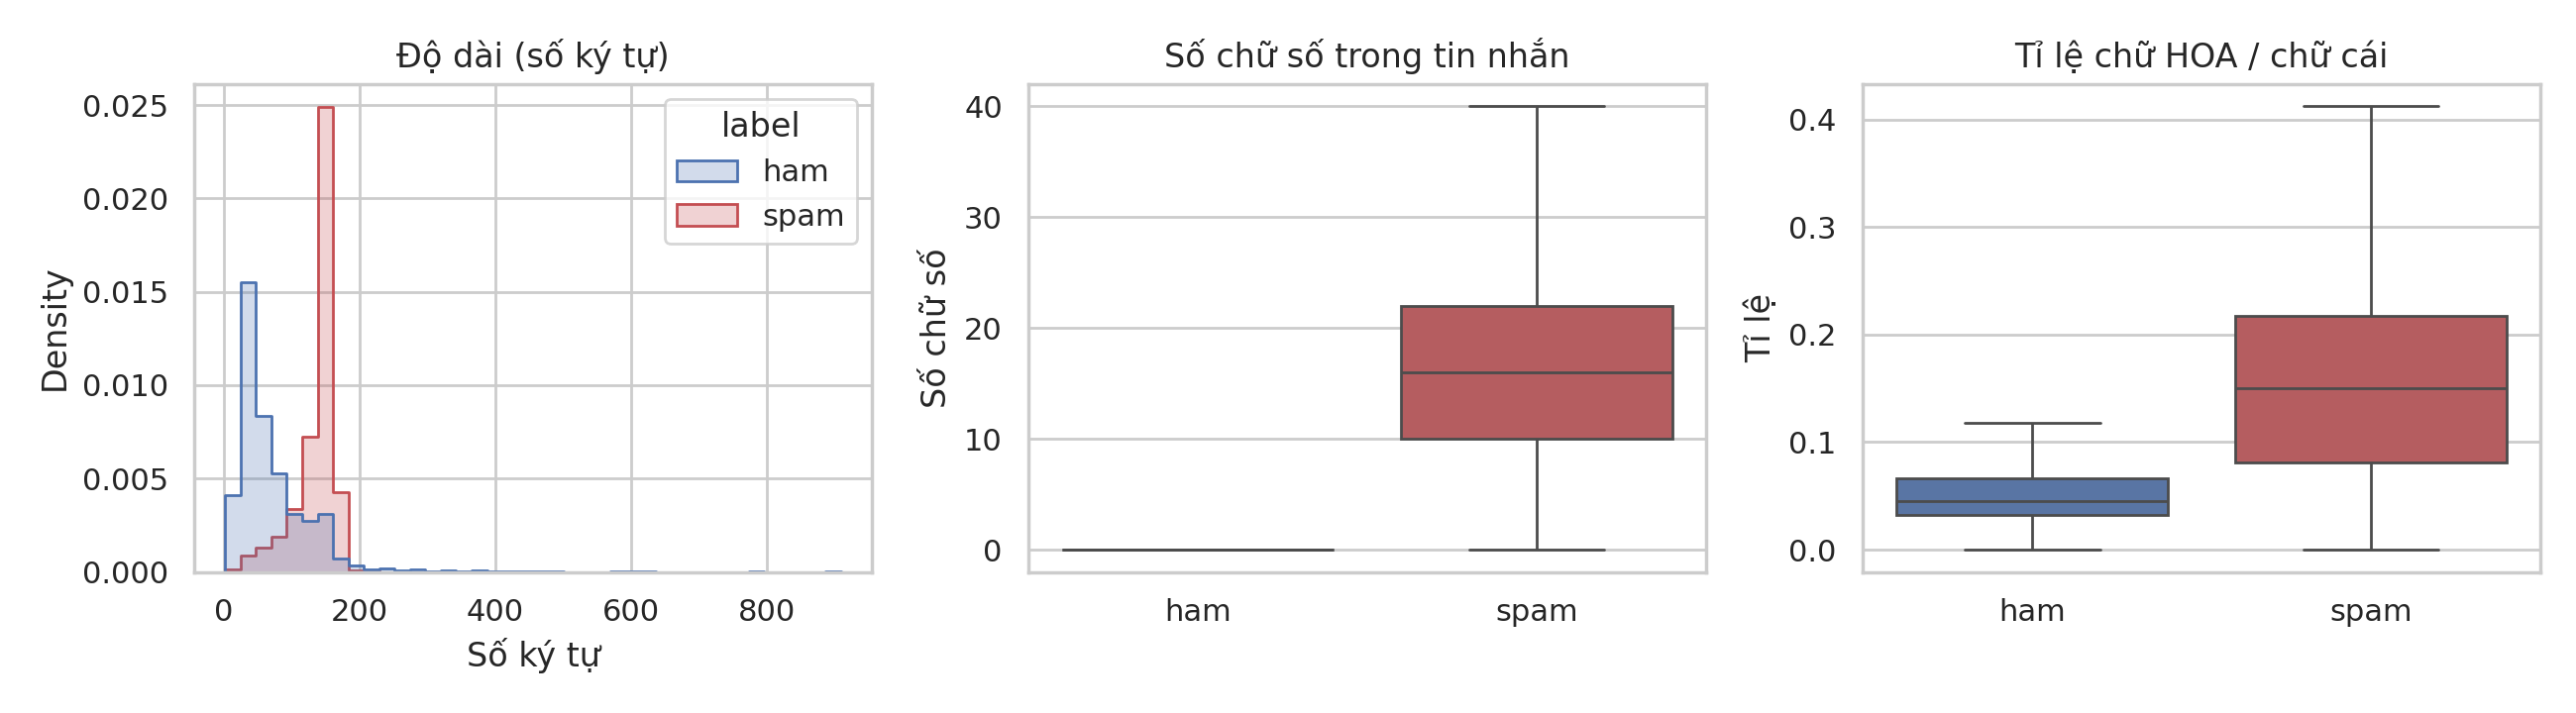

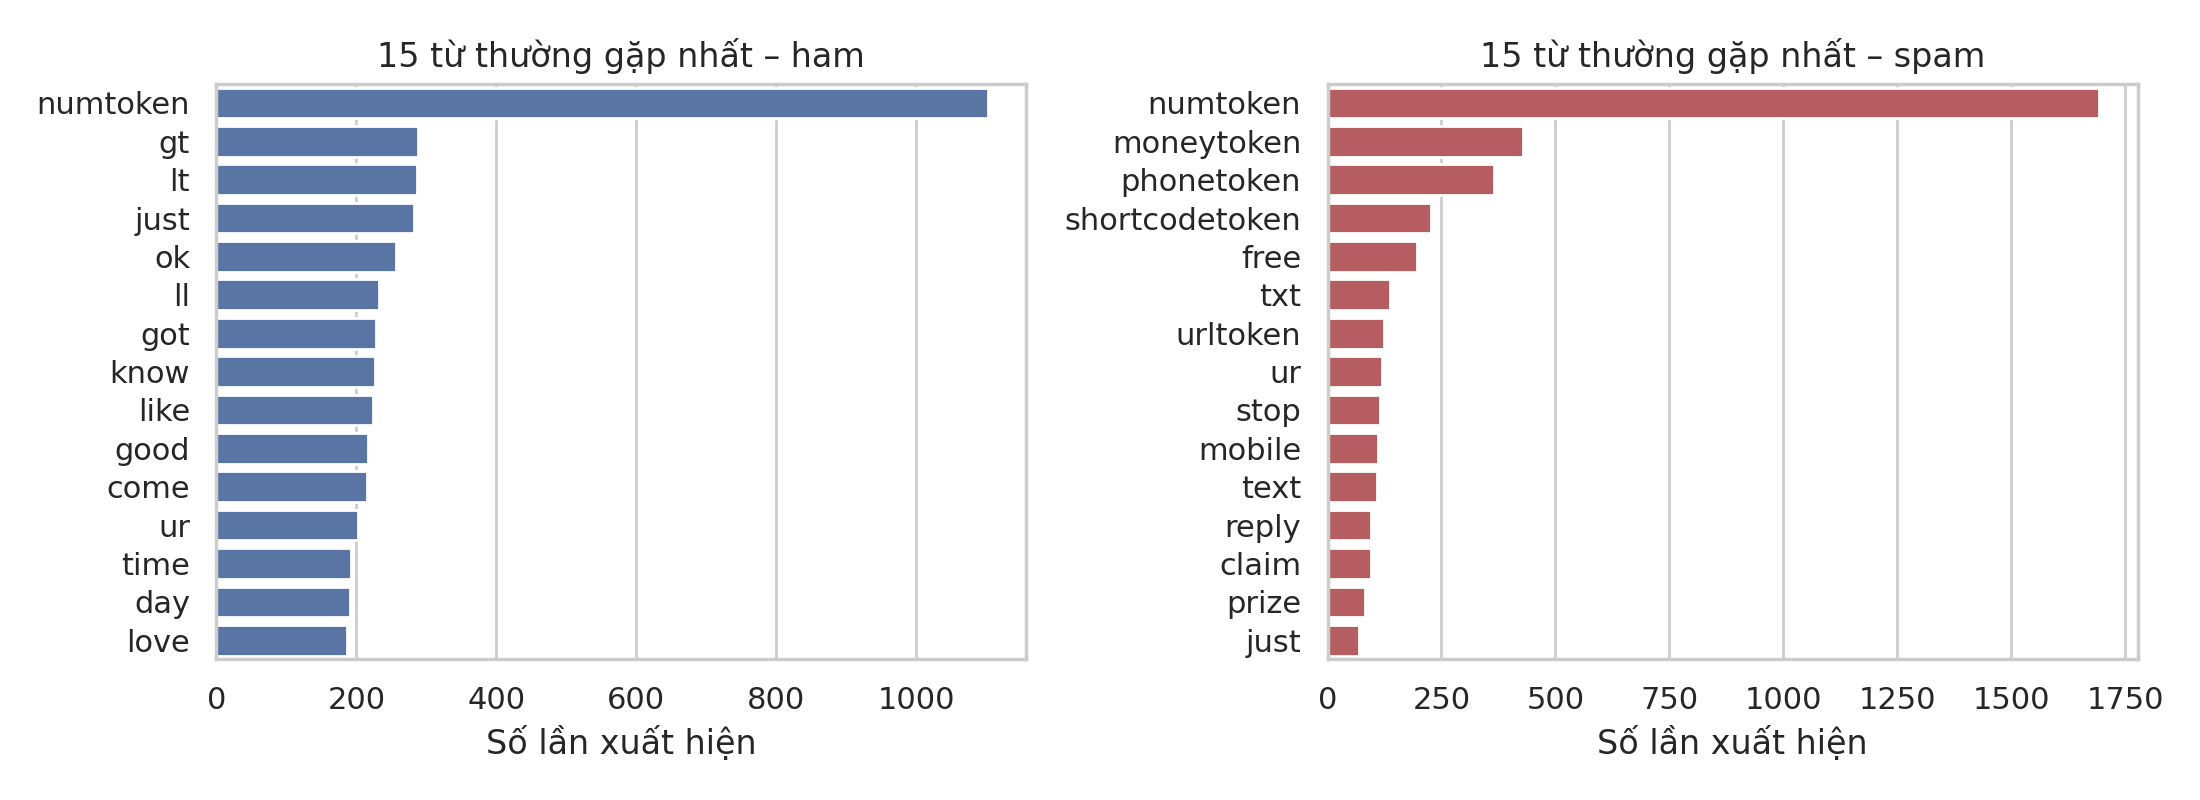

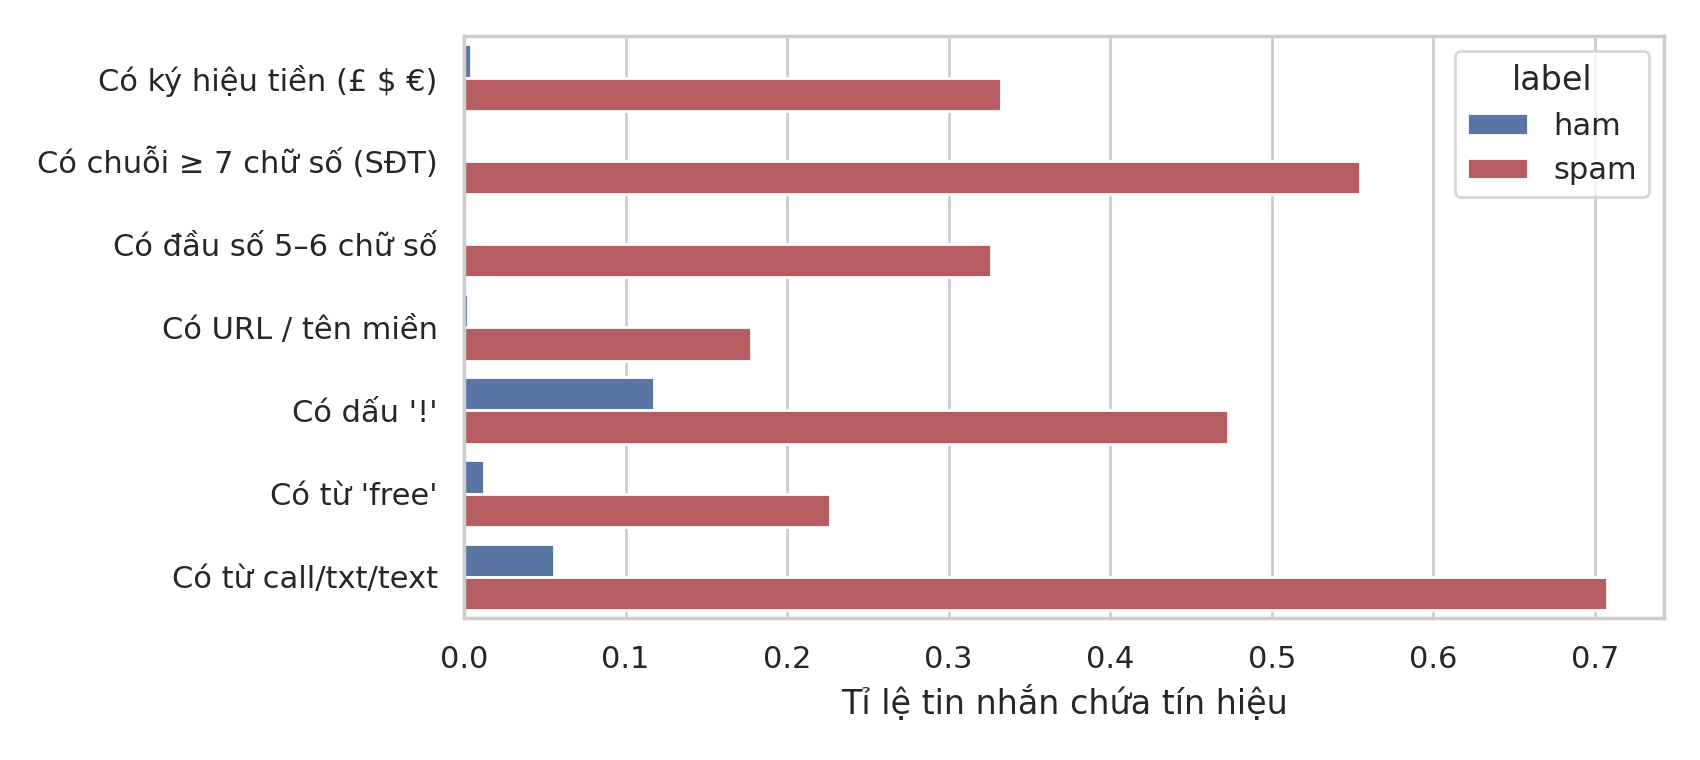

In [4]:
for f in ["eda_label_distribution", "eda_length_features", "eda_top_words", "eda_signals"]:
    display(Image(filename=str(FIG / f"{f}.png"), width=850))

## 2. Tiền xử lý văn bản
`clean_text` **thay** URL, tiền, số điện thoại, shortcode, số bằng token đại diện thay vì xóa, vì sự *xuất hiện* của chúng là tín hiệu của spam.

In [5]:
examples = [
    "WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461.",
    "Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121 to receive entry",
    "Are we still meeting for lunch tomorrow at 12?",
]
for s in examples:
    print("RAW  :", s); print("CLEAN:", clean_text(s)); print()

RAW  : WINNER!! As a valued network customer you have been selected to receive a £900 prize reward! To claim call 09061701461.
CLEAN: winner as a valued network customer you have been selected to receive a moneytoken prize reward to claim call phonetoken

RAW  : Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121 to receive entry
CLEAN: free entry in numtoken a wkly comp to win fa cup final tkts text fa to shortcodetoken to receive entry

RAW  : Are we still meeting for lunch tomorrow at 12?
CLEAN: are we still meeting for lunch tomorrow at numtoken



## 3. Chia dữ liệu
Chia 80/20 có phân tầng. Vectorizer nằm **trong Pipeline** nên chỉ được fit trên tập train (không rò rỉ).

In [6]:
Xtr, Xte, ytr, yte = split(df)
print(f"train = {len(Xtr)} (spam {int(ytr.sum())}) | test = {len(Xte)} (spam {int(yte.sum())})")

train = 4136 (spam 522) | test = 1035 (spam 131)


## 4. Baseline: một Pipeline từ đầu đến cuối (chạy ngay)

In [7]:
# Baseline NB: văn bản raw + BoW + tham số mặc định
base = make_pipeline(make_vectorizer("bow", "raw"), "nb").fit(Xtr, ytr)
res = evaluate(base, Xte, yte)
pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in res.items()}, name="NB baseline")

accuracy       0.9816
precision      0.9516
recall         0.9008
f1             0.9255
f1_macro       0.9575
mcc            0.9155
roc_auc        0.9810
pr_auc         0.9650
tn           898.0000
fp             6.0000
fn            13.0000
tp           118.0000
Name: NB baseline, dtype: float64

In [8]:
# Thử tự cấu hình: BoW + clean_text + NB(alpha=0.1) – cấu hình tốt nhất theo CV trong báo cáo
my = make_pipeline(make_vectorizer("bow", "clean", ngram=(1, 1), min_df=2), "nb", alpha=0.1).fit(Xtr, ytr)
pd.Series({k: round(v, 4) if isinstance(v, float) else v for k, v in evaluate(my, Xte, yte).items()}, name="NB tinh chỉnh")

accuracy       0.9855
precision      0.9328
recall         0.9542
f1             0.9434
f1_macro       0.9675
mcc            0.9352
roc_auc        0.9880
pr_auc         0.9758
tn           895.0000
fp             9.0000
fn             6.0000
tp           125.0000
Name: NB tinh chỉnh, dtype: float64

## 5. Huấn luyện lại toàn bộ thí nghiệm (tùy chọn, ~10 phút trên 1 CPU)
Chạy GridSearchCV cho NB/K-NN/Cây và các thí nghiệm A–I. Mặc định **tắt** để dùng kết quả đã lưu.

In [9]:
RUN_FULL = False   # đổi thành True để chạy lại
if RUN_FULL:
    import experiments, error_analysis
    experiments.main(); error_analysis.main()
else:
    print("Bỏ qua – dùng kết quả đã lưu trong results/ và models/")

Bỏ qua – dùng kết quả đã lưu trong results/ và models/


## 6. Kết quả các thí nghiệm

### 6.1 Tiền xử lý × vector hóa (NB mặc định)

In [10]:
pd.read_csv(TAB / "expA_preprocess_vectorizer.csv").round(4)

,prep,vec,n_features,cv_f1,cv_std,accuracy,precision,recall,f1,fp,fn
0,raw,BOW,7698,0.9371,0.0210,0.9816,0.9516,0.9008,0.9255,6,13
1,raw,TF-IDF,7698,0.7498,0.0410,0.9527,1.0000,0.6260,0.7700,0,49
2,clean,BOW,6788,0.9403,0.0265,0.9865,0.9466,0.9466,0.9466,7,7
3,clean,TF-IDF,6788,0.8148,0.0412,0.9691,1.0000,0.7557,0.8609,0,32
4,clean_stop,BOW,6522,0.9399,0.0228,0.9894,0.9615,0.9542,0.9579,5,6
5,clean_stop,TF-IDF,6522,0.8885,0.0305,0.9768,0.9908,0.8244,0.9000,1,23


### 6.2 So sánh thuật toán (baseline và tinh chỉnh) trên tập test

In [11]:
C = pd.read_csv(TAB / "expC_final_results.csv")
C[["model", "cv_f1", "accuracy", "precision", "recall", "f1", "mcc", "roc_auc", "pr_auc", "fp", "fn"]].round(4)

,model,cv_f1,accuracy,precision,recall,f1,mcc,roc_auc,pr_auc,fp,fn
0,Multinomial NB – baseline,0.9371,0.9816,0.9516,0.9008,0.9255,0.9155,0.9810,0.9650,6,13
1,K-NN – baseline,0.4457,0.9072,1.0000,0.2672,0.4217,0.4915,0.8173,0.6530,0,96
2,Decision Tree – baseline,0.8356,0.9739,0.9000,0.8931,0.8966,0.8816,0.9394,0.8173,13,14
3,Multinomial NB – tinh chỉnh,0.9554,0.9855,0.9328,0.9542,0.9434,0.9352,0.9880,0.9758,9,6
4,K-NN – tinh chỉnh,0.9288,0.9845,0.9675,0.9084,0.9370,0.9288,0.9929,0.9790,4,12
5,Decision Tree – tinh chỉnh,0.9231,0.9836,0.9672,0.9008,0.9328,0.9242,0.9593,0.9022,4,13


{
  "nb": {
    "clf__alpha": 0.1,
    "vec": "BoW ng(1, 1) min_df=2 max_df=1.0",
    "cv_f1": 0.955373889268626
  },
  "knn": {
    "clf__metric": "cosine",
    "clf__n_neighbors": 11,
    "clf__weights": "distance",
    "vec": "TF-IDF ng(1, 1) min_df=2 max_df=1.0",
    "cv_f1": 0.9287638607155204
  },
  "dt": {
    "clf__criterion": "gini",
    "clf__max_depth": 10,
    "clf__min_samples_leaf": 2,
    "vec": "TF-IDF ng(1, 1) min_df=2 max_df=1.0",
    "cv_f1": 0.9231137821671641
  }
}


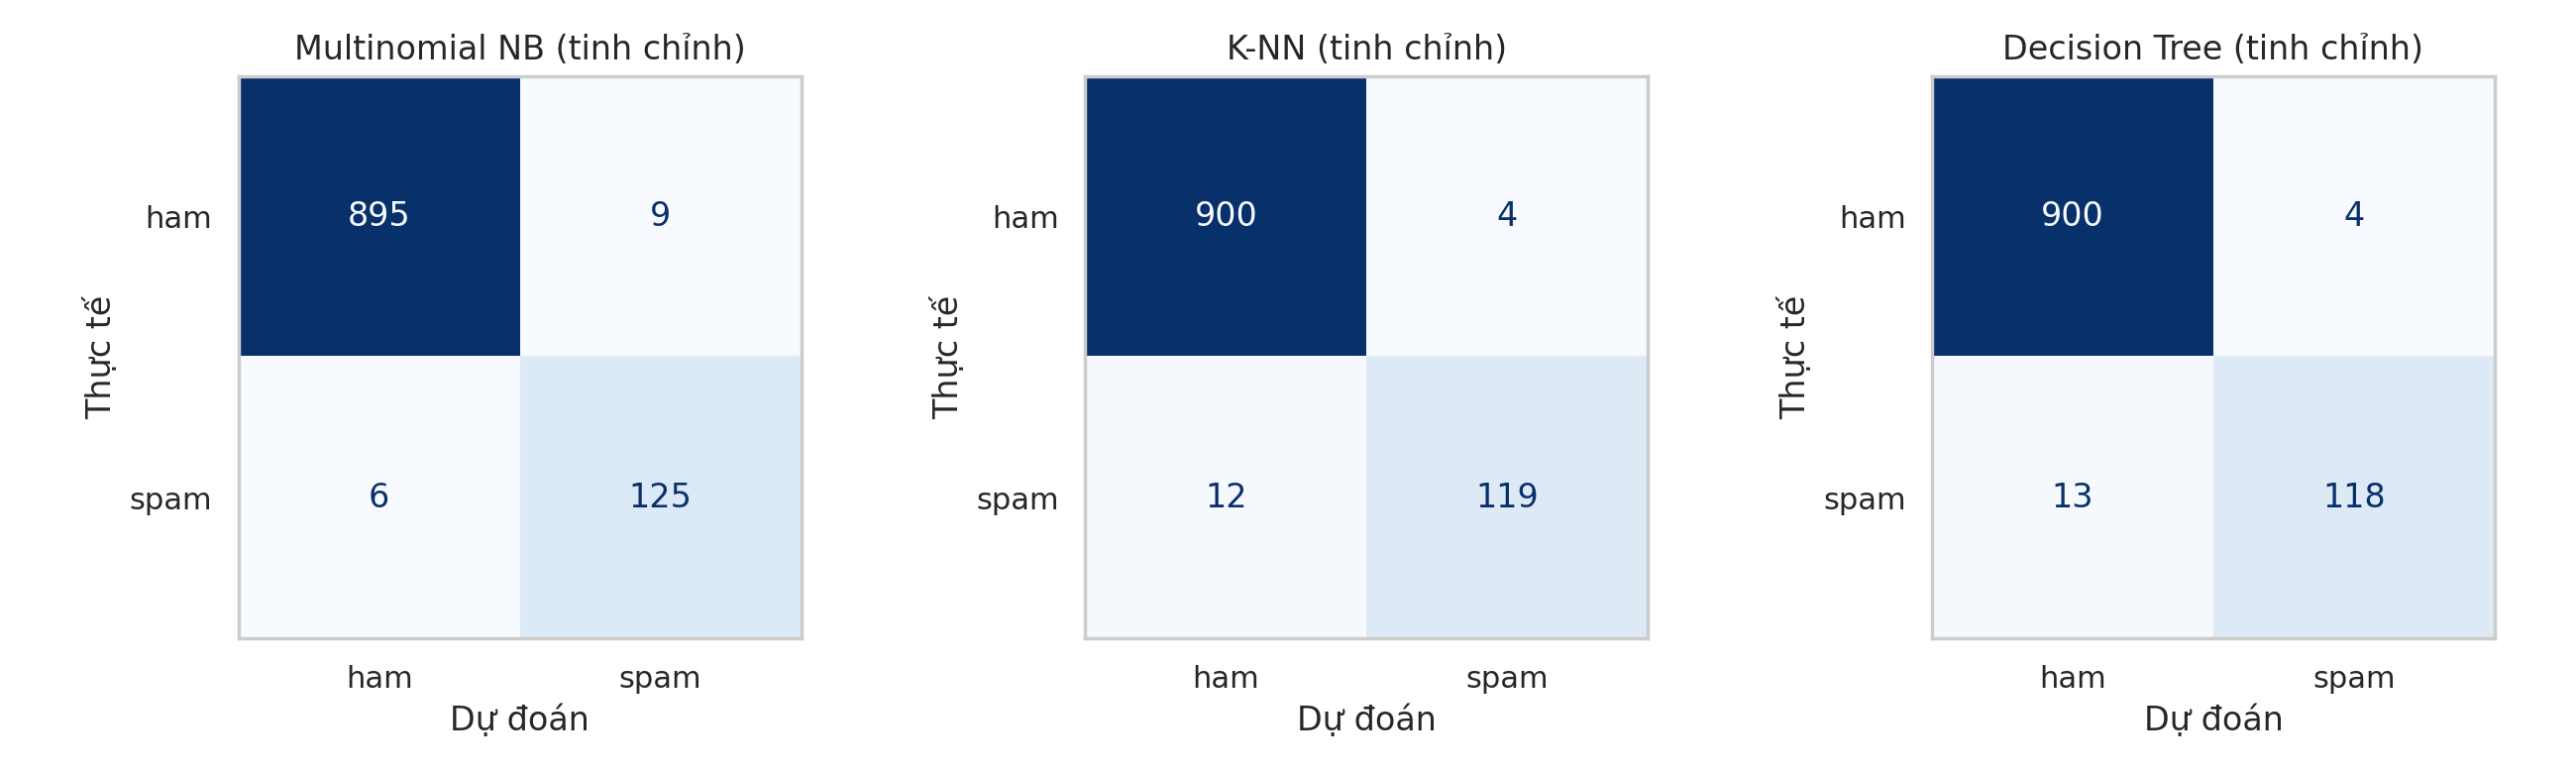

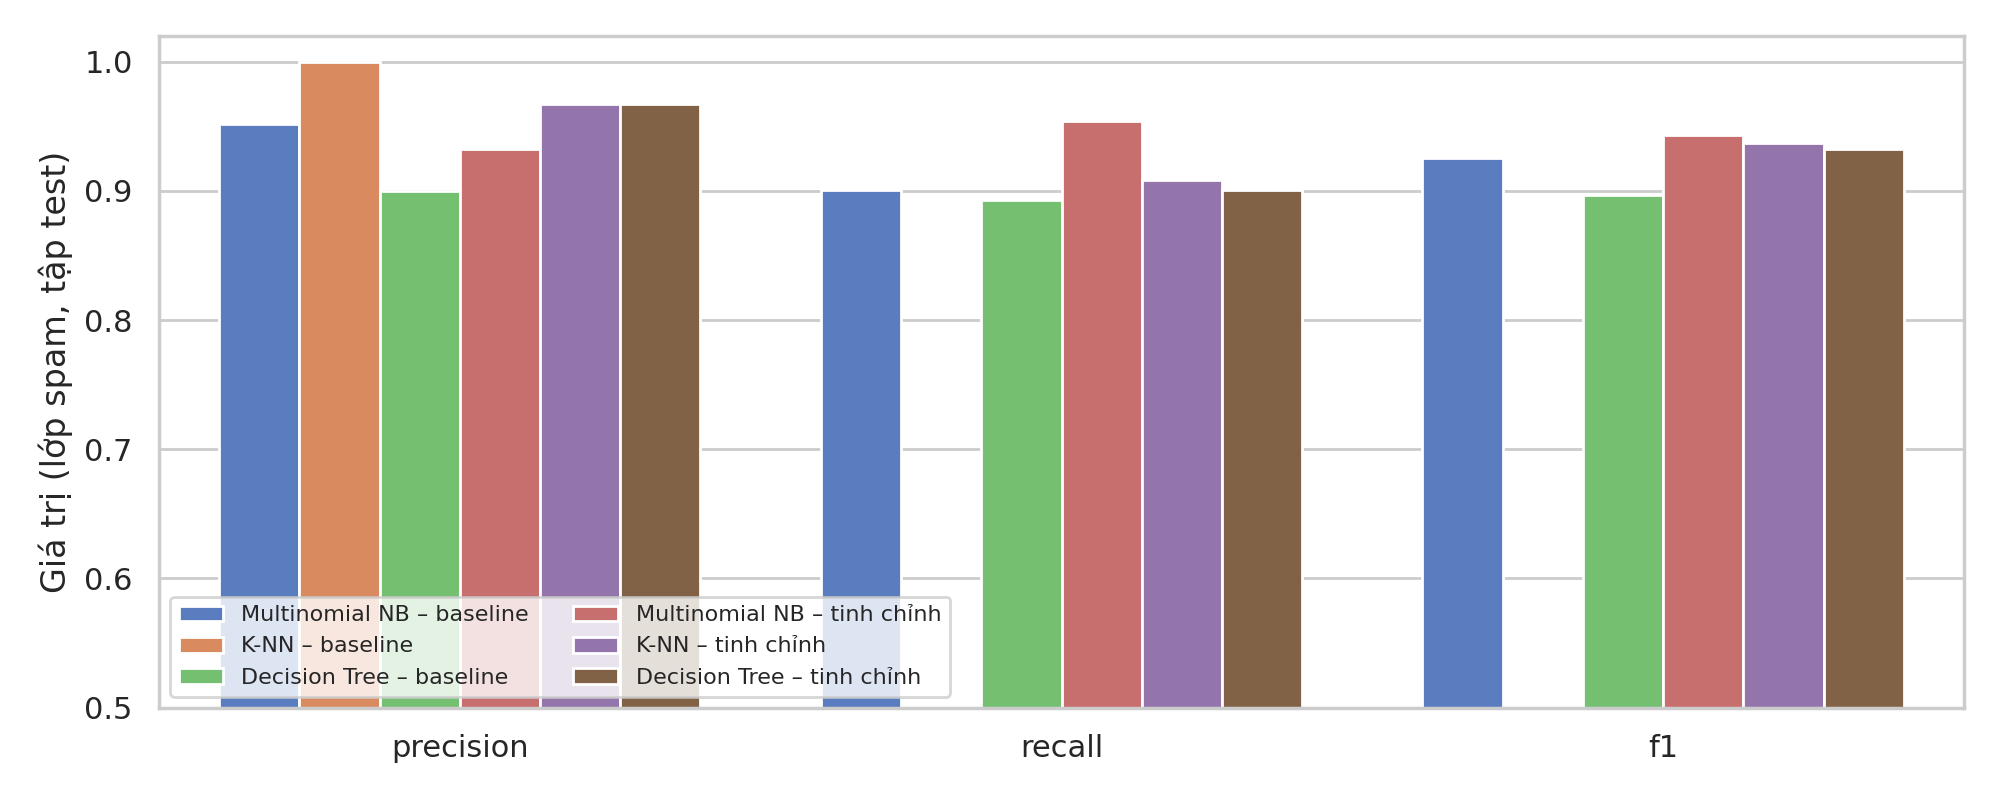

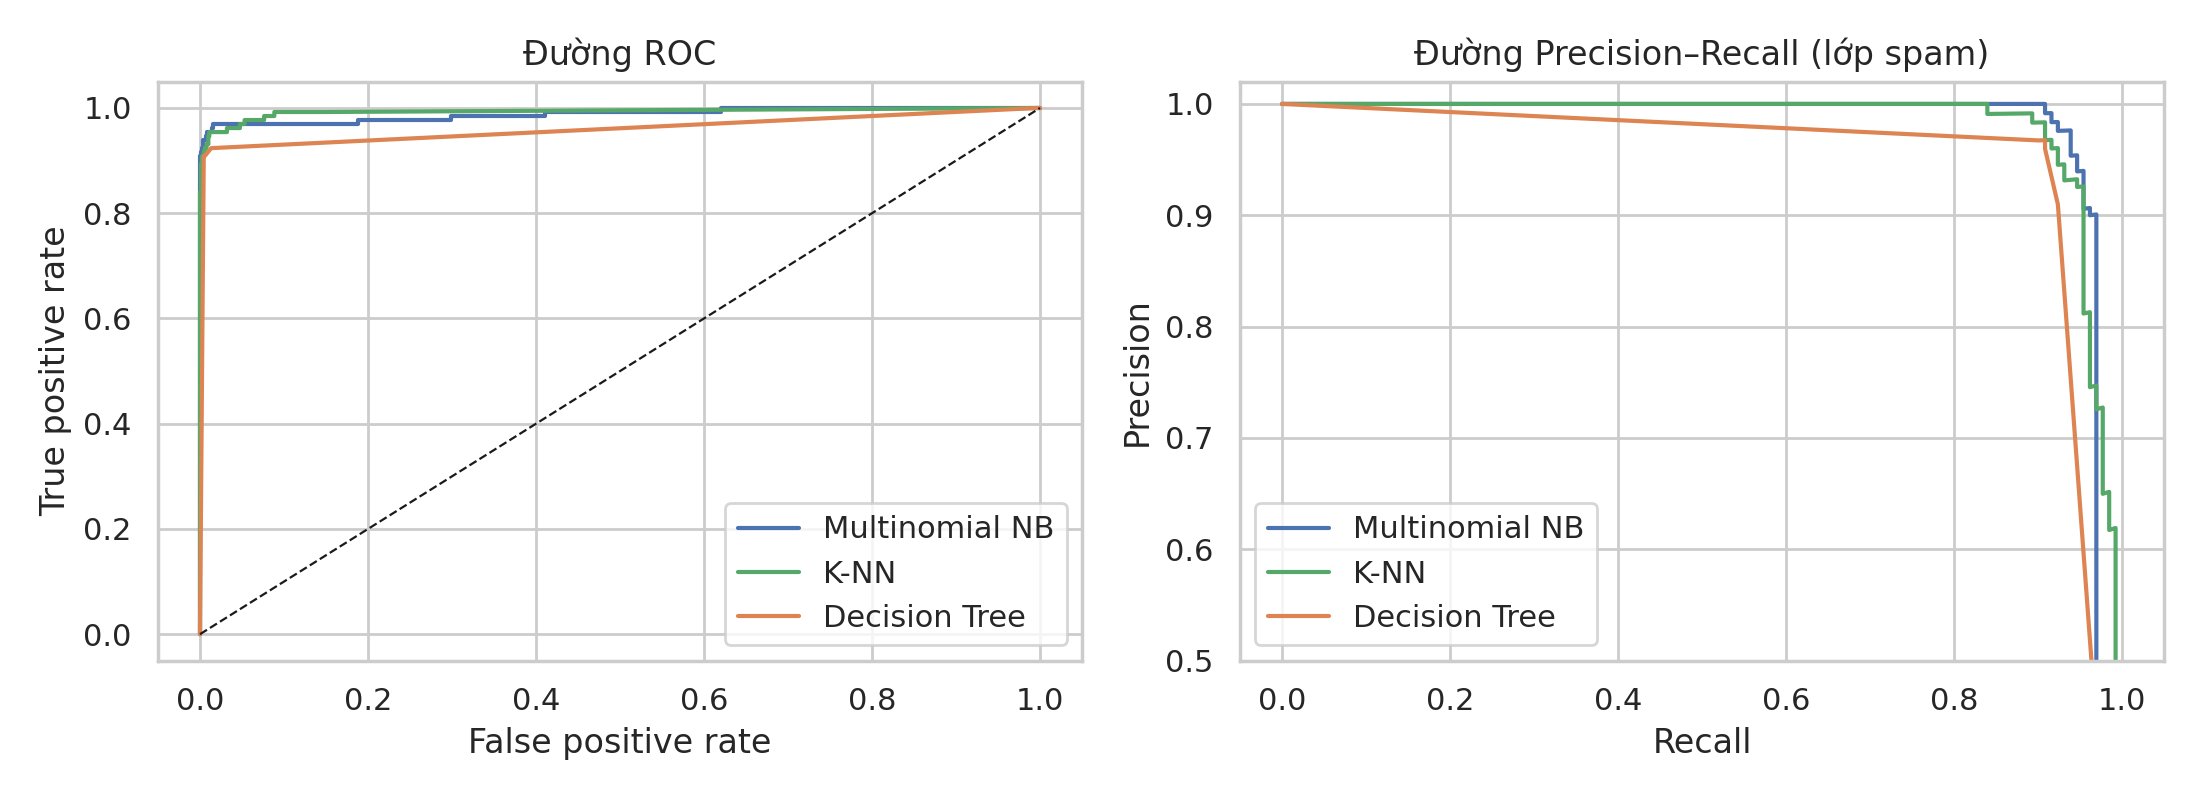

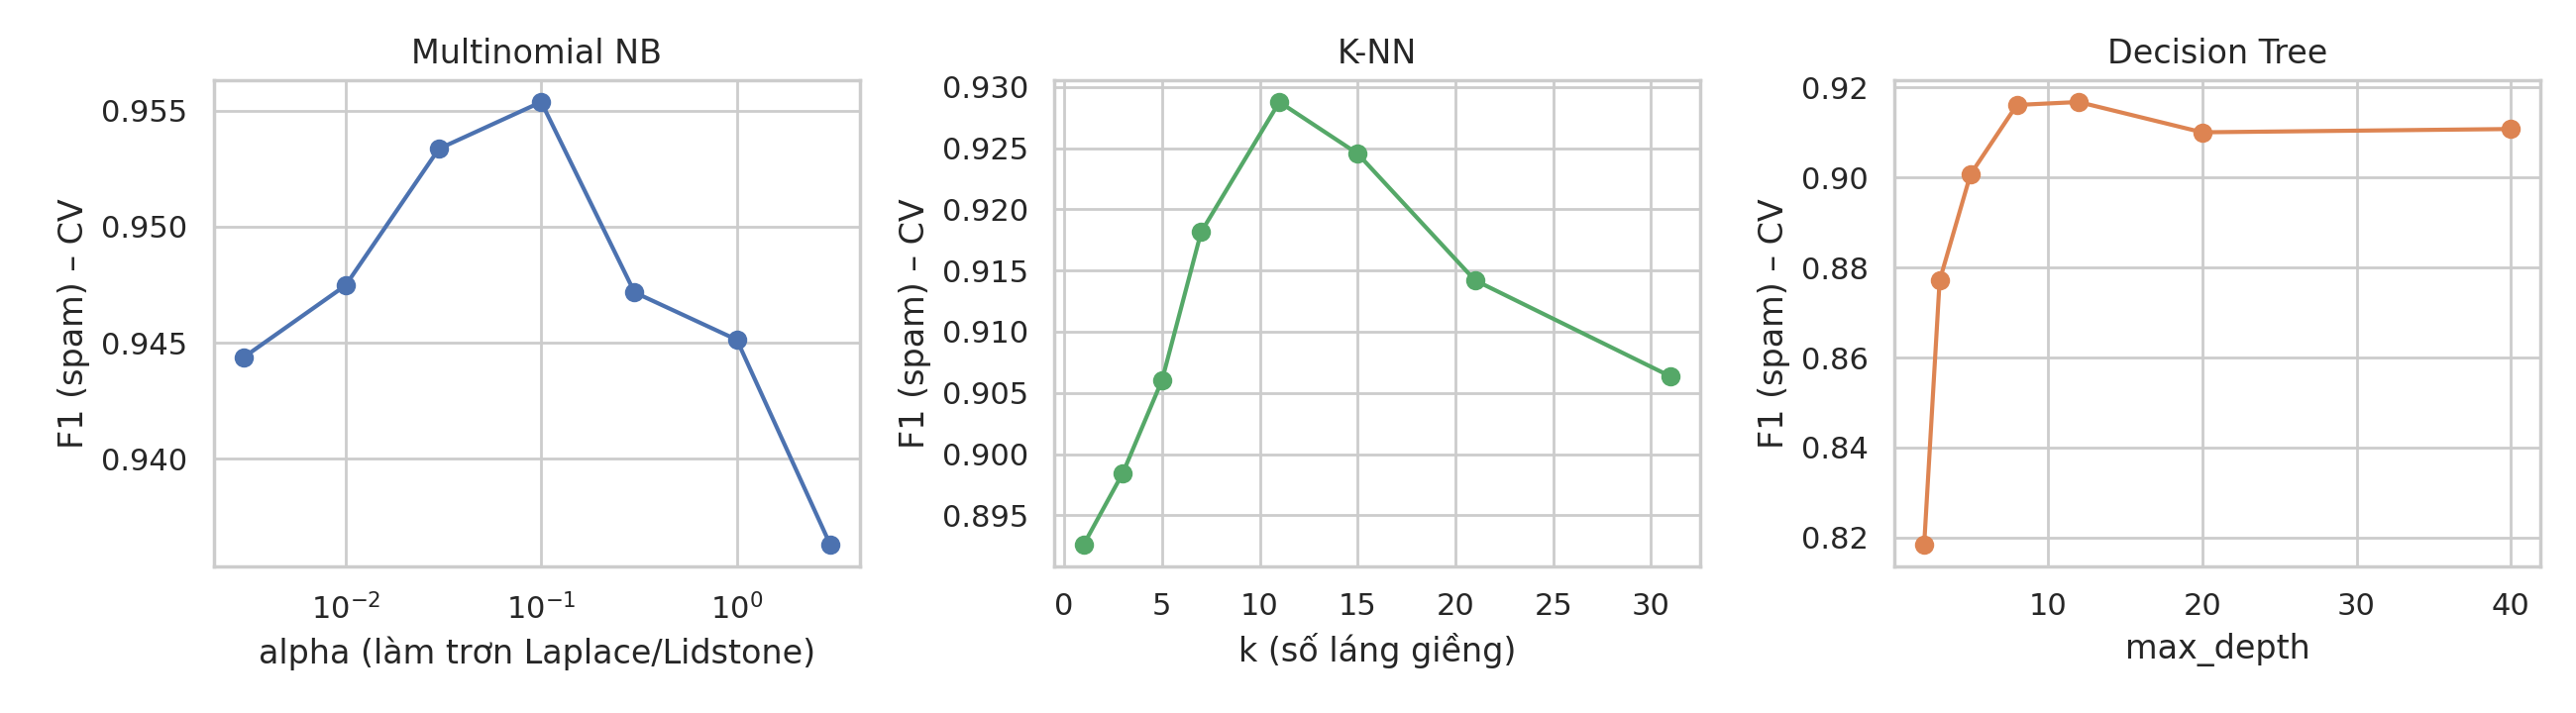

In [12]:
print(json.dumps(json.load(open(TAB / "best_params.json")), indent=2, ensure_ascii=False))
for f in ["expC_confusion_matrices", "expC_metric_comparison", "expC_roc_pr", "expD_sensitivity"]:
    display(Image(filename=str(FIG / f"{f}.png"), width=850))

### 6.3 Ổn định theo seed và khoảng tin cậy bootstrap
Tập test chỉ có 131 spam nên chênh lệch nhỏ giữa các mô hình **không có ý nghĩa thống kê**.

In [13]:
display(pd.read_csv(TAB / "expE_seed_stability.csv").round(4))
display(pd.read_csv(TAB / "expI_bootstrap_f1.csv").round(4))
pd.read_csv(TAB / "expI_bootstrap_diff.csv").round(4)

,model,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,accuracy_mean,accuracy_std
0,Multinomial NB – baseline,0.9779,0.0111,0.9344,0.0192,0.9554,0.0075,0.9890,0.0018
1,K-NN – baseline,1.0000,0.0000,0.3405,0.0257,0.5075,0.0286,0.9165,0.0032
2,Decision Tree – baseline,0.8750,0.0366,0.8565,0.0533,0.8640,0.0172,0.9660,0.0036
3,Multinomial NB – tinh chỉnh,0.9415,0.0176,0.9481,0.0267,0.9444,0.0092,0.9859,0.0022
4,K-NN – tinh chỉnh,0.9504,0.0179,0.9038,0.0434,0.9261,0.0254,0.9818,0.0059
5,Decision Tree – tinh chỉnh,0.9509,0.0141,0.8809,0.0245,0.9143,0.0111,0.9791,0.0025


,model,f1_test,ci_low,ci_high
0,Multinomial NB – baseline,0.9255,0.8918,0.9565
1,K-NN – baseline,0.4217,0.3270,0.5150
2,Decision Tree – baseline,0.8966,0.8559,0.9333
3,Multinomial NB – tinh chỉnh,0.9434,0.9127,0.9697
4,K-NN – tinh chỉnh,0.9370,0.9057,0.9668
5,Decision Tree – tinh chỉnh,0.9328,0.8996,0.9630


,so_sanh,diff_f1,ci_low,ci_high,p_diff_le_0
0,Multinomial NB – tinh chỉnh − Multinomial NB – baseline,0.0179,-0.0090,0.0455,0.1010
1,Multinomial NB – tinh chỉnh − K-NN – tinh chỉnh,0.0064,-0.0241,0.0383,0.3535
2,Multinomial NB – tinh chỉnh − Decision Tree – tinh chỉnh,0.0106,-0.0264,0.0449,0.2910
3,K-NN – tinh chỉnh − Decision Tree – tinh chỉnh,0.0042,-0.0280,0.0362,0.4180


### 6.4 Tin trùng lặp, ngưỡng quyết định, đặc trưng thủ công

In [14]:
display(pd.read_csv(TAB / "expF_duplicates.csv").round(4))
display(pd.read_csv(TAB / "expG_threshold.csv").round(4))
pd.read_csv(TAB / "expH_meta_features.csv").round(4)

,model,f1_dedup,f1_keep_dups,recall_dedup,recall_keep_dups
0,Multinomial NB,0.9434,0.9595,0.9542,0.9530
1,K-NN,0.9370,0.9444,0.9084,0.9128
2,Decision Tree,0.9328,0.9412,0.9008,0.9128


,threshold,oof_precision,oof_recall,test_precision,test_recall,test_f1,test_fp,test_fn
0,0.1,0.8648,0.9559,0.8247,0.9695,0.8912,27,4
1,0.2,0.9071,0.9540,0.8819,0.9695,0.9236,17,4
2,0.3,0.9307,0.9521,0.9000,0.9618,0.9299,14,5
3,0.4,0.9502,0.9502,0.9124,0.9542,0.9328,12,6
4,0.5,0.9612,0.9502,0.9328,0.9542,0.9434,9,6
5,0.6,0.9706,0.9483,0.9398,0.9542,0.9470,8,6
6,0.7,0.9724,0.9464,0.9466,0.9466,0.9466,7,7
7,0.8,0.9782,0.9444,0.9685,0.9389,0.9535,4,8
8,0.9,0.9858,0.9330,0.9762,0.9389,0.9572,3,8


,model,cv_f1_text,cv_f1_text_meta,test_f1_text,test_f1_text_meta,recall_text,recall_text_meta,precision_text,precision_text_meta
0,Multinomial NB,0.9554,0.9545,0.9434,0.9509,0.9542,0.9618,0.9328,0.9403
1,K-NN,0.9288,0.9459,0.9370,0.9255,0.9084,0.9008,0.9675,0.9516
2,Decision Tree,0.9231,0.9118,0.9328,0.9333,0.9008,0.9084,0.9672,0.9597


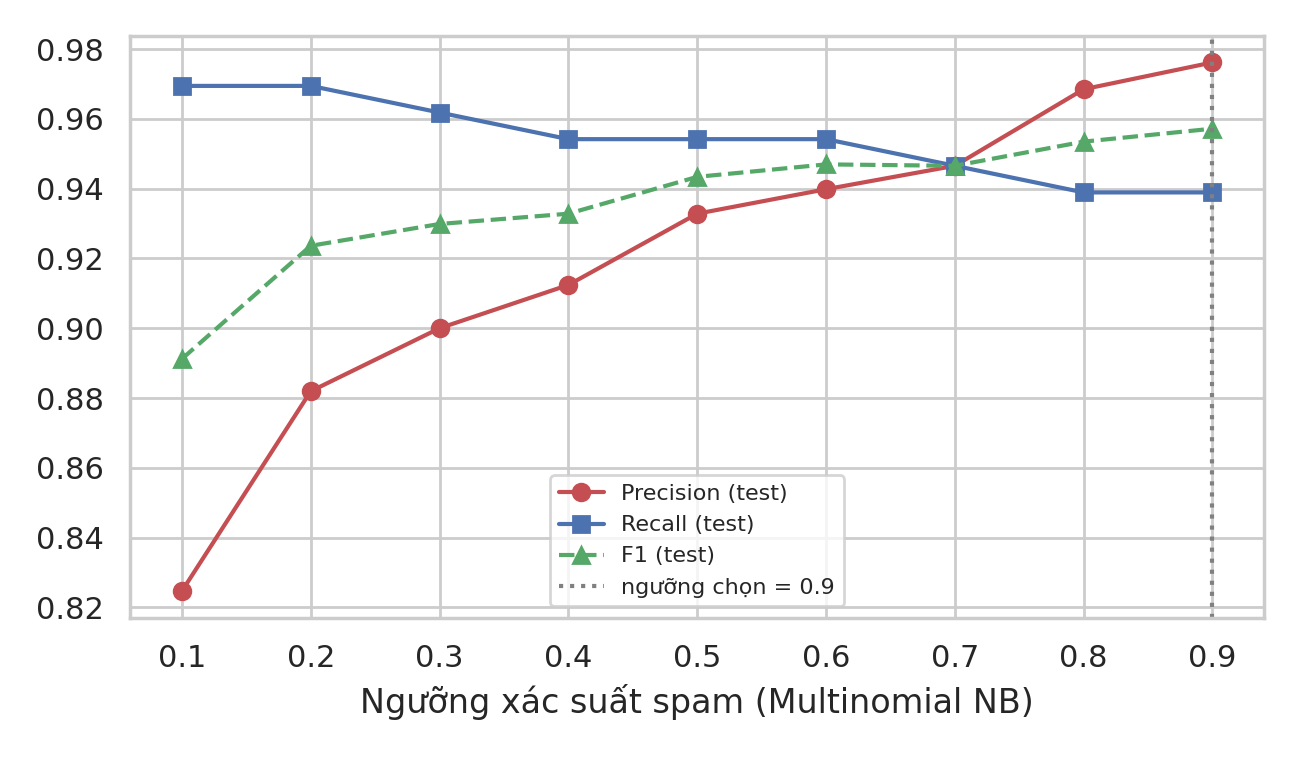

In [15]:
display(Image(filename=str(FIG / "expG_threshold.png"), width=500))

## 7. Phân tích lỗi (mô hình đã lưu)

In [16]:
NAMES = {"nb": "Multinomial NB", "knn": "K-NN", "dt": "Decision Tree"}
models = {n: joblib.load(ROOT / "models" / f"{n}_best.joblib") for n in NAMES}
te = pd.DataFrame({"text": Xte.values, "y": yte.values})
for n, m in models.items():
    te[n] = m.predict(Xte)
    print(f"{NAMES[n]:15s} lỗi = {(te[n] != te.y).sum():2d} | FP = {((te[n]==1)&(te.y==0)).sum()} | FN = {((te[n]==0)&(te.y==1)).sum()}")
print("Tin bị cả 3 mô hình đoán sai:", int(((te.nb != te.y) & (te.knn != te.y) & (te.dt != te.y)).sum()))

Multinomial NB  lỗi = 15 | FP = 9 | FN = 6


K-NN            lỗi = 16 | FP = 4 | FN = 12
Decision Tree   lỗi = 17 | FP = 4 | FN = 13
Tin bị cả 3 mô hình đoán sai: 5


In [17]:
te["p_nb"] = models["nb"].predict_proba(Xte)[:, 1]
fn = te[(te.y == 1) & (te.nb == 0)].sort_values("p_nb")[["p_nb", "text"]]
fp = te[(te.y == 0) & (te.nb == 1)].sort_values("p_nb", ascending=False)[["p_nb", "text"]]
print("=== FN: spam bị bỏ lọt (NB) ==="); display(fn.round(3))
print("=== FP: tin hợp lệ bị chặn nhầm (NB) ==="); display(fp.round(3))

=== FN: spam bị bỏ lọt (NB) ===


,p_nb,text
486,0.000,In The Simpsons Movie released in July 2007 name the band that died at the start of th...
273,0.000,Babe: U want me dont u baby! Im nasty and have a thing 4 filthyguys. Fancy a rude time...
255,0.000,Would you like to see my XXX pics they are so hot they were nearly banned in the uk!
223,0.000,"Xmas & New Years Eve tickets are now on sale from the club, during the day from 10am t..."
654,0.285,"Latest News! Police station toilet stolen, cops have nothing to go on!"
453,0.336,Missed call alert. These numbers called but left no message. 07008009200


=== FP: tin hợp lệ bị chặn nhầm (NB) ===


,p_nb,text
210,0.998,Nokia phone is lovly..
313,0.969,Have you laid your airtel line to rest?
711,0.953,Unlimited texts. Limited minutes.
128,0.804,Are you free now?can i call now?
603,0.789,K:)eng rocking in ashes:)
474,0.789,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove...
642,0.741,Your daily text from me â a favour this time
823,0.648,"Received, understood n acted upon!"
221,0.548,Glad to see your reply.


In [18]:
display(pd.read_csv(TAB / "nb_top_features.csv").round(2))
display(pd.read_csv(TAB / "dt_top_features.csv").round(3))
pd.read_csv(TAB / "errors_by_length.csv").round(4)

,Từ (spam),log-odds,Từ (ham),log-odds
0,shortcodetoken,8.81,gt,-6.42
1,claim,7.85,lt,-6.41
2,prize,7.75,he,-6.21
3,nokia,7.36,lor,-5.94
4,tone,7.13,she,-5.71
5,guaranteed,7.01,later,-5.41
6,ppm,6.98,really,-5.25
7,cs,6.87,doing,-5.24
8,awarded,6.76,say,-5.21
9,ringtone,6.71,ask,-5.19


,Đặc trưng,Độ quan trọng
0,moneytoken,0.490
1,phonetoken,0.238
2,shortcodetoken,0.098
3,urltoken,0.055
4,service,0.013
5,claim,0.012
6,reply,0.011
7,your,0.010
8,mobile,0.009
9,it,0.007


,Độ dài (ký tự),Số tin,Tỉ lệ spam,Lỗi Multinomial NB,Lỗi K-NN,Lỗi Decision Tree
0,<40,318,0.0063,0.0220,0.0031,0.0063
1,40–79,323,0.0217,0.0093,0.0124,0.0155
2,80–119,146,0.0822,0.0068,0.0205,0.0137
3,≥120,248,0.4435,0.0161,0.0323,0.0323


## 8. Dự đoán tin nhắn mới

In [19]:
def predict(text, model="nb", threshold=0.5):
    p = float(models[model].predict_proba([text])[0, 1])
    return f"[{model}] P(spam) = {p:.3f} -> {'SPAM' if p >= threshold else 'HAM'}"

tests = [
    "WINNER!! You have won a £1000 prize. Call 09061701461 to claim, valid 12 hours only",
    "Are we still meeting for lunch tomorrow at 12?",
    "Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121 to receive entry",
    "Ok lor I will reach home by 8",
]
for t in tests:
    print(t[:70]); print("  ", predict(t, "nb"), "|", predict(t, "knn"), "|", predict(t, "dt"))
# Thử tin của bạn:
# print(predict("nội dung tin nhắn ở đây (tiếng Anh)", "nb", threshold=0.9))

WINNER!! You have won a £1000 prize. Call 09061701461 to claim, valid 
   [nb] P(spam) = 1.000 -> SPAM | [knn] P(spam) = 1.000 -> SPAM | [dt] P(spam) = 1.000 -> SPAM
Are we still meeting for lunch tomorrow at 12?
   [nb] P(spam) = 0.000 -> HAM | [knn] P(spam) = 0.000 -> HAM | [dt] P(spam) = 0.009 -> HAM
Free entry in 2 a wkly comp to win FA Cup final tkts. Text FA to 87121
   [nb] P(spam) = 1.000 -> SPAM | [knn] P(spam) = 1.000 -> SPAM | [dt] P(spam) = 1.000 -> SPAM
Ok lor I will reach home by 8
   [nb] P(spam) = 0.000 -> HAM | [knn] P(spam) = 0.000 -> HAM | [dt] P(spam) = 0.009 -> HAM
